# 01 — Delivery SLA Breach & ETA Regression: EDA, Model Benchmark & Threshold Tuning
Benchmarks 5 classifiers (`is_late`) and 5 regressors (`delivery_days`) on the real Olist Brazilian E-Commerce dataset, with zoomed operating-region charts and a business cost simulator.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier, CatBoostRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    mean_absolute_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    root_mean_squared_error,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier, XGBRegressor

sys.path.append(str(Path.cwd().parent))
from train import (
    ARTIFACTS_DIR,
    load_contract,
    load_olist_dataset,
    make_synthetic_logistics_data,
    resolve_olist_dir,
)

contract, schema_hash = load_contract()
feature_cols = [f["name"] for f in contract["features"]]

olist_dir = resolve_olist_dir()
if olist_dir is not None:
    dataset_label = "Real Olist E-Commerce Dataset"
    df = load_olist_dataset(olist_dir)
    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["is_late"], random_state=42)

    # Leak-free target encoding: compute seller_late_rate strictly on train_df
    seller_stats = train_df.groupby("seller_id")["is_late"].agg(["mean", "count"])
    valid_sellers = seller_stats[seller_stats["count"] >= 5]["mean"]
    train_df, test_df = train_df.copy(), test_df.copy()
    train_df["seller_late_rate"] = train_df["seller_id"].map(valid_sellers).astype(np.float32)
    test_df["seller_late_rate"] = test_df["seller_id"].map(valid_sellers).astype(np.float32)
else:
    dataset_label = "Synthetic Logistics Dataset"
    df = make_synthetic_logistics_data()
    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["is_late"], random_state=42)

X_train, X_test = train_df[feature_cols].astype(np.float32), test_df[feature_cols].astype(np.float32)
y_train, y_test = train_df["is_late"].values, test_df["is_late"].values
y_reg_train, y_reg_test = train_df["delivery_days"].values, test_df["delivery_days"].values

print(f"Dataset: {dataset_label} (schema_hash={schema_hash})")
print(f"Train rows: {len(X_train):,} | Test rows: {len(X_test):,} | Late rate: {y_test.mean():.2%} | Mean ETA: {y_reg_test.mean():.2f}d")
print("\nMissing values in test split:")
print(X_test.isna().mean().map("{:.2%}".format))

Dataset: Real Olist E-Commerce Dataset (schema_hash=fe66b8873d6c)
Train rows: 76,793 | Test rows: 19,199 | Late rate: 8.10% | Mean ETA: 12.43d

Missing values in test split:
distance_km         0.00%
weight_grams        0.00%
seller_late_rate    4.11%
is_weekend          0.00%
freight_ratio       0.00%
dtype: str


In [2]:
# 1. Classification Benchmark (is_late)
lr = LogisticRegression(max_iter=500).fit(X_train.fillna(0.0), y_train)
rf_m = RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42).fit(X_train, y_train)
cb_m = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0, allow_writing_files=False).fit(X_train, y_train)
xgb_m = XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.08, random_state=42).fit(X_train, y_train)
lgb_m = LGBMClassifier(n_estimators=120, num_leaves=31, learning_rate=0.08, random_state=42, verbose=-1).fit(X_train, y_train)

probs = {
    "LogisticRegression": lr.predict_proba(X_test.fillna(0.0))[:, 1],
    "RandomForest": rf_m.predict_proba(X_test)[:, 1],
    "CatBoost": cb_m.predict_proba(X_test)[:, 1],
    "XGBoost": xgb_m.predict_proba(X_test)[:, 1],
    "LightGBM": lgb_m.predict_proba(X_test)[:, 1],
}

t = contract["threshold"]
rows = []
for name, p in probs.items():
    preds = (p >= t).astype(int)
    rows.append({
        "Model": name,
        "PR-AUC": round(average_precision_score(y_test, p), 4),
        "Precision": round(precision_score(y_test, preds, zero_division=0), 4),
        "Recall": round(recall_score(y_test, preds, zero_division=0), 4),
        "F1": round(f1_score(y_test, preds, zero_division=0), 4),
    })
pd.DataFrame(rows).sort_values("PR-AUC", ascending=False)

,Model,PR-AUC,Precision,Recall,F1
1,RandomForest,0.1316,0.1414,0.3537,0.2021
4,LightGBM,0.1288,0.1402,0.3614,0.2020
2,CatBoost,0.1288,0.1380,0.3402,0.1964
3,XGBoost,0.1279,0.1381,0.3550,0.1988
0,LogisticRegression,0.0975,0.1364,0.1164,0.1256


Saved chart to /home/gun/work/github.com/gunawanwijaya/apprentice/01-delivery-sla-breach/artifacts/pr_curve_threshold.png


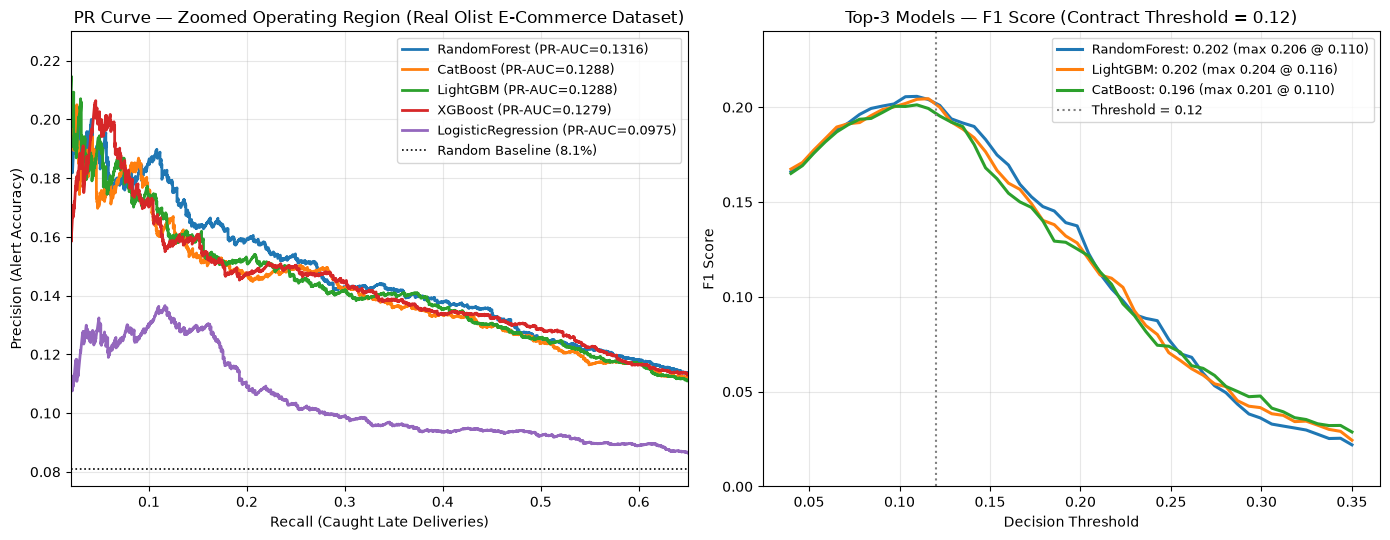

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Sort all models descending by PR-AUC
ranked = sorted(
    [(name, p, average_precision_score(y_test, p)) for name, p in probs.items()],
    key=lambda x: x[2],
    reverse=True,
)

# Left: Zoomed Precision-Recall Curve (legend sorted by PR-AUC)
base_rate = y_test.mean()
for name, p, ap in ranked:
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rec, prec, lw=2, label=f"{name} (PR-AUC={ap:.4f})")

axes[0].axhline(base_rate, color="black", linestyle=":", lw=1.2, label=f"Random Baseline ({base_rate:.1%})")
axes[0].set_title(f"PR Curve — Zoomed Operating Region ({dataset_label})")
axes[0].set_xlabel("Recall (Caught Late Deliveries)")
axes[0].set_ylabel("Precision (Alert Accuracy)")
axes[0].set_xlim(0.02, 0.65)
axes[0].set_ylim(0.075, 0.23)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(alpha=0.3)

# Right: Top-3 Models F1 Threshold Tuning Comparison (sorted by F1 at contract threshold)
thresholds = np.linspace(0.04, 0.35, 50)
t_contract = contract["threshold"]

top3 = sorted(
    ranked[:3],
    key=lambda x: f1_score(y_test, x[1] >= t_contract, zero_division=0),
    reverse=True,
)

for name, p, _ in top3:
    f1s = [f1_score(y_test, p >= th, zero_division=0) for th in thresholds]
    f1_at_t = f1_score(y_test, p >= t_contract, zero_division=0)
    peak_idx = int(np.argmax(f1s))
    axes[1].plot(
        thresholds,
        f1s,
        lw=2.2,
        label=f"{name}: {f1_at_t:.3f} (max {f1s[peak_idx]:.3f} @ {thresholds[peak_idx]:.3f})",
    )

axes[1].axvline(t_contract, color="gray", linestyle=":", lw=1.5, label=f"Threshold = {t_contract}")
axes[1].set_title(f"Top-3 Models — F1 Score (Contract Threshold = {t_contract})")
axes[1].set_xlabel("Decision Threshold")
axes[1].set_ylabel("F1 Score")
axes[1].set_ylim(0.0, 0.24)
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
out_img = ARTIFACTS_DIR / "pr_curve_threshold.png"
plt.savefig(out_img, dpi=150)
print(f"Saved chart to {out_img}")
plt.show()

In [4]:
# Business Cost Simulator (Top 3 models):
# False Positive (unnecessary carrier reroute = $2) vs False Negative (late SLA refund/churn = $15)
COST_FP, COST_FN = 2.0, 15.0

summary_rows = []
for name, p, _ in ranked[:3]:
    best = None
    for th in thresholds:
        preds = (p >= th).astype(int)
        fp = int(((preds == 1) & (y_test == 0)).sum())
        fn = int(((preds == 0) & (y_test == 1)).sum())
        total_cost = fp * COST_FP + fn * COST_FN
        if best is None or total_cost < best["total_cost_usd"]:
            best = {
                "Model": name,
                "best_threshold": round(float(th), 3),
                "FP": fp,
                "FN": fn,
                "total_cost_usd": total_cost,
            }
    summary_rows.append(best)

cost_summary = pd.DataFrame(summary_rows).sort_values("total_cost_usd")
cost_summary

,Model,best_threshold,FP,FN,total_cost_usd
0,RandomForest,0.116,3611,968,21742.0
2,LightGBM,0.116,3687,958,21744.0
1,CatBoost,0.135,2364,1144,21888.0


In [5]:
# 2. ETA Regression Benchmark (delivery_days)
ridge = Ridge(alpha=1.0).fit(X_train.fillna(0.0), y_reg_train)
rf_r = RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42).fit(X_train, y_reg_train)
cb_r = CatBoostRegressor(iterations=300, depth=6, learning_rate=0.08, random_seed=42, verbose=0, allow_writing_files=False).fit(X_train, y_reg_train)
xgb_r = XGBRegressor(n_estimators=120, max_depth=5, learning_rate=0.08, random_state=42).fit(X_train, y_reg_train)
lgb_r = LGBMRegressor(n_estimators=120, num_leaves=31, learning_rate=0.08, random_state=42, verbose=-1).fit(X_train, y_reg_train)

reg_preds = {
    "Ridge": ridge.predict(X_test.fillna(0.0)),
    "RandomForestReg": rf_r.predict(X_test),
    "CatBoostReg": cb_r.predict(X_test),
    "XGBRegressor": xgb_r.predict(X_test),
    "LGBMRegressor": lgb_r.predict(X_test),
}

reg_rows = []
for name, pr in reg_preds.items():
    reg_rows.append({
        "Regressor": name,
        "MAE (days)": round(float(mean_absolute_error(y_reg_test, pr)), 4),
        "RMSE (days)": round(float(root_mean_squared_error(y_reg_test, pr)), 4),
        "R2": round(float(r2_score(y_reg_test, pr)), 4),
    })
reg_df = pd.DataFrame(reg_rows).sort_values("MAE (days)", ascending=True)
reg_df

/home/gun/work/github.com/gunawanwijaya/apprentice/01-delivery-sla-breach/ml/.venv/lib/python3.12/site-packages/sklearn/linear_model/_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 1.3934974008034118e-10.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


,Regressor,MAE (days),RMSE (days),R2
4,LGBMRegressor,5.1377,7.4689,0.2656
1,RandomForestReg,5.1411,7.4823,0.2629
3,XGBRegressor,5.1470,7.4833,0.2627
2,CatBoostReg,5.1587,7.4975,0.2599
0,Ridge,5.4280,7.8023,0.1985


Saved chart to /home/gun/work/github.com/gunawanwijaya/apprentice/01-delivery-sla-breach/artifacts/eta_regression_eval.png


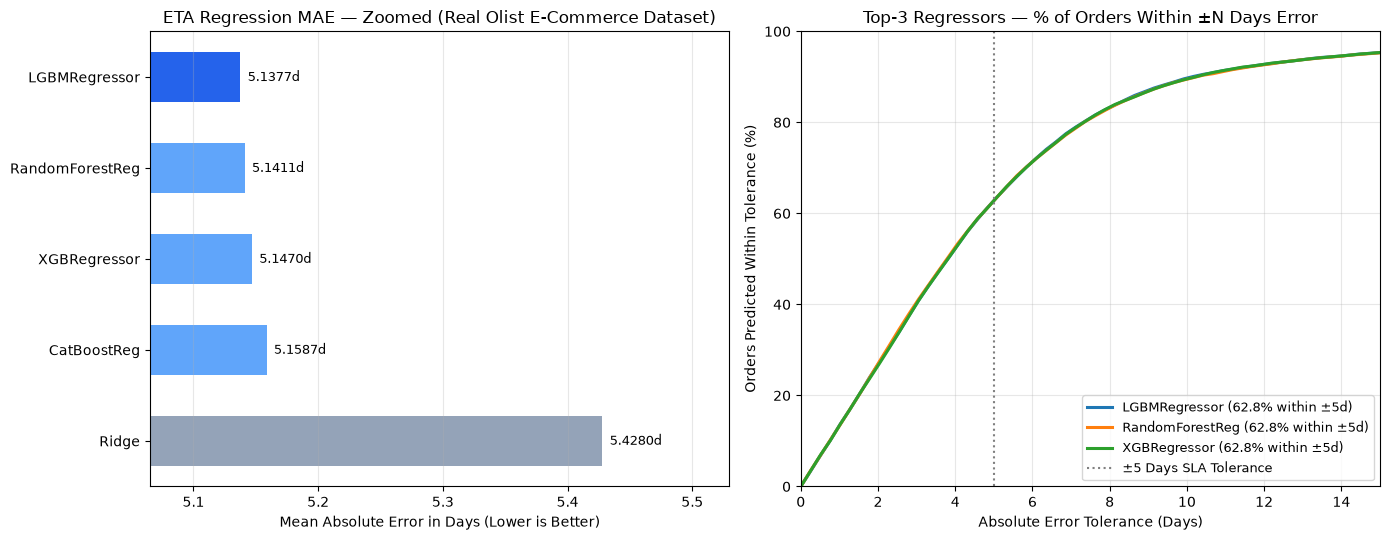

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: Zoomed MAE Comparison (highlights gap between tree ensembles vs. linear Ridge)
min_mae, max_mae = reg_df["MAE (days)"].min(), reg_df["MAE (days)"].max()
pad = max((max_mae - min_mae) * 0.25, 0.05)
colors = ["#2563eb" if i == 0 else "#60a5fa" if i < 4 else "#94a3b8" for i in range(len(reg_df))]
bars = axes[0].barh(reg_df["Regressor"], reg_df["MAE (days)"], color=colors, height=0.55)
axes[0].invert_yaxis()
axes[0].set_xlim(min_mae - pad, max_mae + pad * 1.4)
for bar, val in zip(bars, reg_df["MAE (days)"]):
    axes[0].text(val + pad * 0.08, bar.get_y() + bar.get_height() / 2, f"{val:.4f}d", va="center", fontsize=9)
axes[0].set_title(f"ETA Regression MAE — Zoomed ({dataset_label})")
axes[0].set_xlabel("Mean Absolute Error in Days (Lower is Better)")
axes[0].grid(axis="x", alpha=0.3)

# Right: Top-3 Regressors Cumulative Absolute Error Curve (Zoomed 0-15 days)
err_grid = np.linspace(0, 15, 60)
for name in reg_df["Regressor"].head(3):
    abs_err = np.abs(y_reg_test - reg_preds[name])
    within_pct = [(abs_err <= d).mean() * 100 for d in err_grid]
    within_5d = (abs_err <= 5.0).mean() * 100
    axes[1].plot(err_grid, within_pct, lw=2.2, label=f"{name} ({within_5d:.1f}% within ±5d)")

axes[1].axvline(5.0, color="gray", linestyle=":", lw=1.5, label="±5 Days SLA Tolerance")
axes[1].set_title("Top-3 Regressors — % of Orders Within ±N Days Error")
axes[1].set_xlabel("Absolute Error Tolerance (Days)")
axes[1].set_ylabel("Orders Predicted Within Tolerance (%)")
axes[1].set_xlim(0, 15)
axes[1].set_ylim(0, 100)
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
out_reg = ARTIFACTS_DIR / "eta_regression_eval.png"
plt.savefig(out_reg, dpi=150)
print(f"Saved chart to {out_reg}")
plt.show()